# Seleção de Algoritmos e Modelagem — Predição de Carga Alta (EVCOMX)

Segue a **Aula 05 do bootcamp** (slides citados como "slide N") e continua a pasta
`feature_selection/`. O roteiro é o "passo a passo da modelagem" do slide 36:

| Passo da aula (slide 36) | Seção |
|---|---|
| 1. Regressão ou classificação? | 1 |
| 2. Métrica pelo custo do erro | 2 |
| 3. Treino/teste separados e baseline | 3 e 4 |
| 4. Pipeline e 2 a 4 algoritmos | 5 |
| 5. Comparar com validação cruzada | 6 |
| Hiperparâmetros (slide 24) | 7 |
| Desbalanceamento: pesos × sem peso × subamostragem (Guia de Modelagem §4.4) | 7b |
| 6. Subir de complexidade só se valer a pena (slide 33) | 8 |
| Limiar de decisão (slide 16) | 9 |
| 7. Conferir no teste, uma única vez (slide 35) | 10 |
| Explicar o modelo escolhido | 11 |
| Modelo para uso e arquivos | 12 |

**Rode antes** `EDA/transforma_dataset.py` e `feature_selection/feature_selection.py`:
esta etapa lê os CSVs gerados pela feature selection e não recalcula nenhuma feature.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_validate, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, accuracy_score, recall_score,
                             precision_score, f1_score, fbeta_score, confusion_matrix, precision_recall_curve)

SEED = 42
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.6, "axes.axisbelow": True})
# mesma paleta da EDA e da feature selection
AZUL, VERMELHO, CINZA, LARANJA, VERDE = "#2b6cb0", "#c0392b", "#7f8c8d", "#dd8a2e", "#4a8c4a"

## 0. Ler os arquivos da feature selection

- `dataset_features_completo.csv`: as 80 candidatas, a coluna `conjunto` (split 70/15/15
  temporal, por corrida) e `carga_alta`.
- `dataset_modelagem_fs.csv`: define o **conjunto FINAL** (6 features com o corte de 2.000 kg da EDA).
- `votos_feature_selection.csv`: define o **consenso (≥ 4 votos, 18 features)**.

`inicio` (data do cestão) é só metadado: serve para ordenar no tempo, nunca entra no modelo.

In [2]:
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "feature_selection").is_dir() and (p / "original_dataset").is_dir())
PASTA_FS = RAIZ / "feature_selection"
PASTA_SAIDA = RAIZ / "selecao_algoritmos"
PASTA_GRAF = PASTA_SAIDA / "graficos"
PASTA_GRAF.mkdir(parents=True, exist_ok=True)

def salvar(nome):
    plt.tight_layout()
    plt.savefig(PASTA_GRAF / f"{nome}.png", dpi=130, bbox_inches="tight")
    plt.show()

for arq in ["dataset_modelagem_fs.csv", "dataset_features_completo.csv", "votos_feature_selection.csv"]:
    assert (PASTA_FS / arq).exists(), f"feature_selection/{arq} não existe: rode o feature_selection.py primeiro!"

META = ["cd_corrida", "nu_carregamento", "conjunto", "inicio"]
fs = pd.read_csv(PASTA_FS / "dataset_modelagem_fs.csv")
df = pd.read_csv(PASTA_FS / "dataset_features_completo.csv")
votos = pd.read_csv(PASTA_FS / "votos_feature_selection.csv", index_col=0)

df["inicio"] = pd.to_datetime(df["inicio"], utc=True, format="ISO8601")
df = df.sort_values(["inicio", "cd_corrida", "nu_carregamento"]).reset_index(drop=True)

FEAT_FINAL = [c for c in fs.columns if c not in META + ["carga_alta"]]
FEAT_CONSENSO = list(votos.index[votos["total"] >= 4])
FEAT_SEM_HIST = [c for c in FEAT_FINAL if not c.startswith("taxa_ca_")]

# conferência: os dois arquivos da feature selection descrevem os mesmos cestões
chk = fs.merge(df[["cd_corrida", "nu_carregamento", "conjunto", "carga_alta"]],
               on=["cd_corrida", "nu_carregamento"], suffixes=("_fs", ""))
assert len(chk) == len(fs) == len(df), "Os CSVs da feature selection não batem entre si."
assert (chk["carga_alta_fs"] == chk["carga_alta"]).all() and (chk["conjunto_fs"] == chk["conjunto"]).all()

CONJUNTOS = {f"final ({len(FEAT_FINAL)})": FEAT_FINAL, f"consenso ({len(FEAT_CONSENSO)})": FEAT_CONSENSO,
             f"final sem histórico ({len(FEAT_SEM_HIST)})": FEAT_SEM_HIST}
NOME_FINAL, NOME_CONS, NOME_SEMH = list(CONJUNTOS)
for nome, cols in CONJUNTOS.items():
    print(f"{nome:28s} {cols}")

treino = df[df.conjunto == "treino"].reset_index(drop=True)
valid = df[df.conjunto == "validacao"].reset_index(drop=True)
teste = df[df.conjunto == "teste"].reset_index(drop=True)
y_tr, y_va, y_te = treino["carga_alta"], valid["carga_alta"], teste["carga_alta"]

final (6)                    ['densidade_media', 'prop_peso_pesado', 'peso_por_ciclo_t', 'taxa_ca_ult5', 'taxa_ca_ult10', 'prop_PACB']
consenso (18)                ['densidade_media', 'prop_peso_pesado', 'peso_por_ciclo_t', 'taxa_ca_ult5', 'taxa_ca_ult10', 'prop_PACB', 'dia_semana', 'prop_leve', 'hhi_materiais', 'max_bloco_leve_m3', 'prop_leve_topo', 'intervalo_medio_min', 'taxa_ca_ult20', 'peso_base_30pct_t', 'prop_OXIC', 'peso_topo_30pct_t', 'prop_ESPR', 'turno_A']
final sem histórico (4)      ['densidade_media', 'prop_peso_pesado', 'peso_por_ciclo_t', 'prop_PACB']


## 1. Que tipo de pergunta? (slides 5 e 6)

"Este cestão vai dar carga alta?" tem resposta **sim ou não**: é **classificação**.
Por isso a regressão linear (slide 14) fica de fora; dos cinco algoritmos da aula, entram a
regressão logística, a árvore de decisão, a Random Forest e o Gradient Boosting.

A duração da parada (`qt_segundos_parada_carga_alta`) daria um problema de regressão, mas
não é a pergunta da EVCOMX e só existe quando a carga alta já aconteceu.

## 2. A métrica, escolhida pelo custo do erro (slides 32 e 34)

Só ~16% dos cestões têm carga alta, então **acurácia engana** (slide 35): quem sempre diz
"normal" acerta ~84%. Usamos:
- **PR-AUC** (precisão média) para **comparar algoritmos**. Não depende do limiar e foca na
  classe rara. Um chute tem PR-AUC igual à taxa de carga alta (~0,16);
- **ROC-AUC** como segunda opinião;
- **recall e precisão** depois de escolher o limiar (seção 9).

**Qual erro custa mais caro?** (slide 32). Perguntamos à EVCOMX por e-mail em 18/10/2026:
alarme falso ou carga alta não detectada. Enquanto a resposta não chega, a seção 9 deixa
**três limiares prontos**, um para cada resposta possível.

## 3. Separação dos dados

O split já vem pronto da feature selection (coluna `conjunto`): 70/15/15 **em ordem de
tempo**, por corrida, definido pelo professor.
- **Treino**: onde os modelos aprendem e onde roda a validação cruzada.
- **Validação**: onde comparamos os algoritmos já ajustados e escolhemos o limiar.
- **Teste**: a prova final, usada **uma única vez** na seção 10 (slide 35).

In [3]:
resumo_split = df.groupby("conjunto").agg(
    cestoes=("carga_alta", "size"), taxa_carga_alta=("carga_alta", "mean"),
    de=("inicio", "min"), ate=("inicio", "max")).loc[["treino", "validacao", "teste"]]
resumo_split["de"] = resumo_split["de"].dt.tz_convert("America/Sao_Paulo").dt.strftime("%d/%m/%Y")
resumo_split["ate"] = resumo_split["ate"].dt.tz_convert("America/Sao_Paulo").dt.strftime("%d/%m/%Y")
resumo_split.round(3)

,cestoes,taxa_carga_alta,de,ate
conjunto,,,,
treino,2473,0.159,14/08/2025,25/04/2026
validacao,513,0.179,25/04/2026,27/06/2026
teste,515,0.146,24/06/2026,04/08/2026


### Validação cruzada **temporal** (adaptação do slide 30)

A aula usa `cross_val_score(cv=5)`, que sorteia as linhas. Aqui isso vazaria o futuro
(Guia EVCOMX §2.2), e as features `taxa_ca_ult5/10` olham para as corridas anteriores.
Então as 5 "provas" andam no tempo, como uma janela que cresce:

| Prova | Treina com | Avalia em |
|---|---|---|
| 1 | bloco 1 | bloco 2 |
| 2 | blocos 1–2 | bloco 3 |
| … | … | … |
| 5 | blocos 1–5 | bloco 6 |

Os blocos são feitos por corrida: os dois cestões da mesma corrida ficam sempre juntos.

In [4]:
def dobras_temporais(dados, n_blocos=6):
    ordem = dados.groupby("cd_corrida")["inicio"].min().sort_values()
    bloco_corrida = pd.Series(np.arange(len(ordem)) * n_blocos // len(ordem), index=ordem.index)
    bloco = dados["cd_corrida"].map(bloco_corrida).to_numpy()
    return [(np.where(bloco <= k)[0], np.where(bloco == k + 1)[0]) for k in range(n_blocos - 1)]

CV = dobras_temporais(treino)
periodo_dobra = []
for i, (a, b) in enumerate(CV, 1):
    ini = treino.loc[b, "inicio"].min().tz_convert("America/Sao_Paulo")
    fim = treino.loc[b, "inicio"].max().tz_convert("America/Sao_Paulo")
    periodo_dobra.append(f"{ini:%d/%m}–{fim:%d/%m}")
    print(f"Prova {i}: treina {len(a):4d} cestões | avalia {len(b):3d} ({periodo_dobra[-1]}), "
          f"taxa de carga alta {treino.loc[b, 'carga_alta'].mean():.2f}")

Prova 1: treina  407 cestões | avalia 417 (26/09–26/10), taxa de carga alta 0.09
Prova 2: treina  824 cestões | avalia 409 (26/10–29/11), taxa de carga alta 0.19
Prova 3: treina 1233 cestões | avalia 415 (29/11–23/01), taxa de carga alta 0.17
Prova 4: treina 1648 cestões | avalia 416 (23/01–13/03), taxa de carga alta 0.12
Prova 5: treina 2064 cestões | avalia 409 (13/03–25/04), taxa de carga alta 0.18


## 4. Baseline: a régua mínima (slides 8 a 11)

Três réguas, como pede o Guia de Modelagem (§4.2):
- **trivial** (`DummyClassifier`): **maioria** (sempre diz "normal": acurácia alta, recall zero)
  e **sorteio** (sorteia "carga alta" na proporção do treino);
- **física / regra de volume**: alarme quando o volume estimado do cestão passa de um limiar
  escolhido **no treino** (melhor F2, no máximo metade dos cestões em alarme). É o que a
  operação poderia fazer hoje, sem ML. A nota sem limiar (PR-AUC) usa o próprio volume como
  "chance";
- **estatística**: a regressão logística com as features finais (seção 5).

Qualquer algoritmo precisa superar as réguas, **na mesma métrica**. A regra do histórico
(só `taxa_ca_ult5`), que se mostrou a régua mais dura, é tratada na análise de modelos.

## 5. Pipeline e algoritmos (slides 13 a 29)

Todas as features são numéricas, então o `ColumnTransformer` do slide 28 não é necessário:
um `Pipeline` basta.
- **Preencher vazios** com a mediana do treino (`taxa_ca_ult5/10` não existem nas primeiras
  corridas da série).
- **Padronizar** só na regressão logística (slide 25: árvores não precisam).
- Tudo aprende **só com o treino** de cada prova: nada espia a validação (slide 27).

`class_weight="balanced"` dá mais peso à classe rara na logística, na árvore e na Random
Forest. O Gradient Boosting do scikit-learn não tem esse parâmetro; como a PR-AUC não depende
do limiar e o limiar é ajustado na seção 9, isso não o prejudica na comparação.

Hiperparâmetros iniciais "de fábrica", próximos dos slides 19, 23 e 24. São ajustados na
seção 7.

In [5]:
def montar(modelo, escala=False):
    passos = [("vazios", SimpleImputer(strategy="median"))]
    if escala:
        passos.append(("escala", StandardScaler()))
    passos.append(("modelo", modelo))
    return Pipeline(passos)

def algoritmos(n_jobs_rf=-1):
    return {
        "Baseline: maioria": montar(DummyClassifier(strategy="most_frequent")),
        "Baseline: sorteio": montar(DummyClassifier(strategy="stratified", random_state=SEED)),
        "Regressão logística": montar(LogisticRegression(max_iter=2000, class_weight="balanced"), escala=True),
        "Árvore de decisão": montar(DecisionTreeClassifier(max_depth=4, min_samples_leaf=20,
                                                           class_weight="balanced", random_state=SEED)),
        "Random Forest": montar(RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                       class_weight="balanced_subsample",
                                                       n_jobs=n_jobs_rf, random_state=SEED)),
        "Gradient Boosting": montar(GradientBoostingClassifier(learning_rate=0.05, n_estimators=200, max_depth=3,
                                                               subsample=0.8, random_state=SEED)),
    }

ALGOS = list(algoritmos())
ALGOS.insert(2, "Baseline: regra de volume")
ALGOS_REAIS = [a for a in ALGOS if not a.startswith("Baseline")]
COMPLEXIDADE = {"Regressão logística": 1, "Árvore de decisão": 2, "Random Forest": 3, "Gradient Boosting": 4}
COR_ALGO = {"Regressão logística": LARANJA, "Árvore de decisão": VERDE, "Random Forest": AZUL,
            "Gradient Boosting": VERMELHO, "Baseline: maioria": CINZA, "Baseline: sorteio": CINZA,
            "Baseline: regra de volume": CINZA}

## 6. Comparação justa: validação cruzada temporal + validação (slide 30)

Para cada conjunto de features e cada algoritmo:
- **CV**: média e desvio da PR-AUC nas 5 provas temporais dentro do treino;
- **validação**: treina no treino inteiro e mede na validação (abr–jun/2026).

As duas medidas respondem coisas diferentes. A CV mostra se o algoritmo é estável ao longo do
treino; a validação mostra se ele aguenta o período mais recente, que já é o regime pós-maio
(ver README da feature selection).

In [6]:
def avaliar(pipe, cols):
    cv = cross_validate(pipe, treino[cols], y_tr, cv=CV,
                        scoring={"PR-AUC": "average_precision", "ROC-AUC": "roc_auc"})
    p = pipe.fit(treino[cols], y_tr).predict_proba(valid[cols])[:, 1]
    return {"CV_PR-AUC": cv["test_PR-AUC"].mean(), "CV_PR-AUC_dp": cv["test_PR-AUC"].std(),
            "CV_ROC-AUC": cv["test_ROC-AUC"].mean(),
            "val_PR-AUC": average_precision_score(y_va, p), "val_ROC-AUC": roc_auc_score(y_va, p),
            "PR-AUC_por_prova": list(np.round(cv["test_PR-AUC"], 4))}

linhas, de_fabrica = [], {}
for nome_conj, cols in CONJUNTOS.items():
    for nome_alg, pipe in algoritmos().items():
        linhas.append({"conjunto": nome_conj, "algoritmo": nome_alg, "n_features": len(cols),
                       **avaliar(pipe, cols)})
        de_fabrica[(nome_conj, nome_alg)] = pipe      # avaliar() deixa o pipe treinado no treino inteiro
tab_fabrica = pd.DataFrame(linhas)

# Baseline físico (Guia de Modelagem §4.2): alarme se volume_m3_total > limiar escolhido no treino
COL_VOL = "volume_m3_total"
def limiar_regra(score, y, beta=2.0, alarmes_max=0.5):
    """Limiar de uma regra 'alarme se score > limiar': melhor F-beta, com no máximo metade em alarme."""
    cand_l = np.unique(np.quantile(score, np.linspace(0.5, 0.99, 50)))
    f = [fbeta_score(y, score > l, beta=beta, zero_division=0) if (score > l).mean() <= alarmes_max else -1
         for l in cand_l]
    return float(cand_l[int(np.argmax(f))])
cv_vol = [average_precision_score(treino.loc[b, "carga_alta"], treino.loc[b, COL_VOL]) for _, b in CV]
cv_vol_roc = [roc_auc_score(treino.loc[b, "carga_alta"], treino.loc[b, COL_VOL]) for _, b in CV]
LIM_VOL = limiar_regra(treino[COL_VOL].to_numpy(), y_tr.to_numpy())
regra_vol = {"algoritmo": "Baseline: regra de volume", "n_features": 1,
             "CV_PR-AUC": np.mean(cv_vol), "CV_PR-AUC_dp": np.std(cv_vol), "CV_ROC-AUC": np.mean(cv_vol_roc),
             "val_PR-AUC": average_precision_score(y_va, valid[COL_VOL]),
             "val_ROC-AUC": roc_auc_score(y_va, valid[COL_VOL]), "PR-AUC_por_prova": list(np.round(cv_vol, 4))}
tab_fabrica = pd.concat([tab_fabrica, pd.DataFrame([{"conjunto": c, **regra_vol} for c in CONJUNTOS])],
                        ignore_index=True)
alarme_vol_va = valid[COL_VOL] > LIM_VOL
print(f"Regra de volume: alarme se volume > {LIM_VOL:.1f} m³ (escolhido no treino). Na validação: "
      f"{100 * alarme_vol_va.mean():.0f} alarmes por 100 cestões, recall {recall_score(y_va, alarme_vol_va):.2f}, "
      f"precisão {precision_score(y_va, alarme_vol_va, zero_division=0):.2f}")
print(f"Referência de chute: PR-AUC = taxa de carga alta (treino {y_tr.mean():.3f}, validação {y_va.mean():.3f})")
tab_fabrica.drop(columns="PR-AUC_por_prova").round(3)

Regra de volume: alarme se volume > 56.4 m³ (escolhido no treino). Na validação: 54 alarmes por 100 cestões, recall 0.42, precisão 0.14
Referência de chute: PR-AUC = taxa de carga alta (treino 0.159, validação 0.179)


,conjunto,algoritmo,n_features,CV_PR-AUC,CV_PR-AUC_dp,CV_ROC-AUC,val_PR-AUC,val_ROC-AUC
0,final (6),Baseline: maioria,6,0.152,0.037,0.500,0.179,0.500
1,final (6),Baseline: sorteio,6,0.149,0.036,0.484,0.187,0.521
2,final (6),Regressão logística,6,0.450,0.158,0.779,0.286,0.668
3,final (6),Árvore de decisão,6,0.372,0.087,0.741,0.296,0.670
4,final (6),Random Forest,6,0.413,0.109,0.763,0.427,0.731
5,final (6),Gradient Boosting,6,0.397,0.078,0.754,0.395,0.730
6,consenso (18),Baseline: maioria,18,0.152,0.037,0.500,0.179,0.500
7,consenso (18),Baseline: sorteio,18,0.149,0.036,0.484,0.187,0.521
8,consenso (18),Regressão logística,18,0.448,0.136,0.783,0.302,0.695
9,consenso (18),Árvore de decisão,18,0.375,0.086,0.745,0.302,0.689


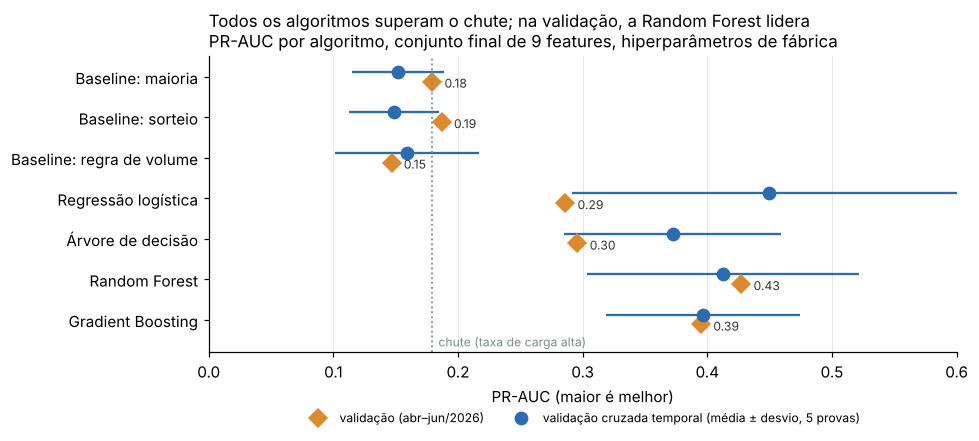

In [7]:
# Gráfico 01: todos os algoritmos x baseline, no conjunto final (CV e validação)
d = tab_fabrica[tab_fabrica.conjunto == NOME_FINAL].set_index("algoritmo").loc[ALGOS[::-1]]
fig, ax = plt.subplots(figsize=(9, 4.2))
ypos = np.arange(len(d))
ax.errorbar(d["CV_PR-AUC"], ypos + 0.12, xerr=d["CV_PR-AUC_dp"], fmt="o", ms=8, color=AZUL,
            ecolor=AZUL, elinewidth=1.5, capsize=0, label="validação cruzada temporal (média ± desvio, 5 provas)")
ax.plot(d["val_PR-AUC"], ypos - 0.12, "D", ms=8, color=LARANJA, label="validação (abr–jun/2026)")
for y, v in zip(ypos, d["val_PR-AUC"]):
    ax.annotate(f"{v:.2f}", (v, y - 0.12), xytext=(8, -4), textcoords="offset points", fontsize=8, color="#333")
ax.axvline(y_va.mean(), color=CINZA, ls=":", lw=1.2)
ax.annotate("chute (taxa de carga alta)", (y_va.mean(), -0.55), xytext=(4, 0), textcoords="offset points",
            fontsize=8, color=CINZA, va="center")
ax.set_yticks(ypos, d.index)
ax.set_xlabel("PR-AUC (maior é melhor)")
ax.set_xlim(0, max(0.6, d[["CV_PR-AUC", "val_PR-AUC"]].max().max() + 0.08))
melhor_val = d.drop(index=[a for a in d.index if a.startswith("Baseline")])["val_PR-AUC"]
ax.set_title(f"Todos os algoritmos superam o chute; na validação, a {melhor_val.idxmax()} lidera\n"
             f"PR-AUC por algoritmo, conjunto final de 9 features, hiperparâmetros de fábrica",
             loc="left", fontsize=11)
ax.set_ylim(-0.8, len(d) - 0.5)
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
ax.grid(axis="y", visible=False)
salvar("01_baseline_vs_algoritmos")

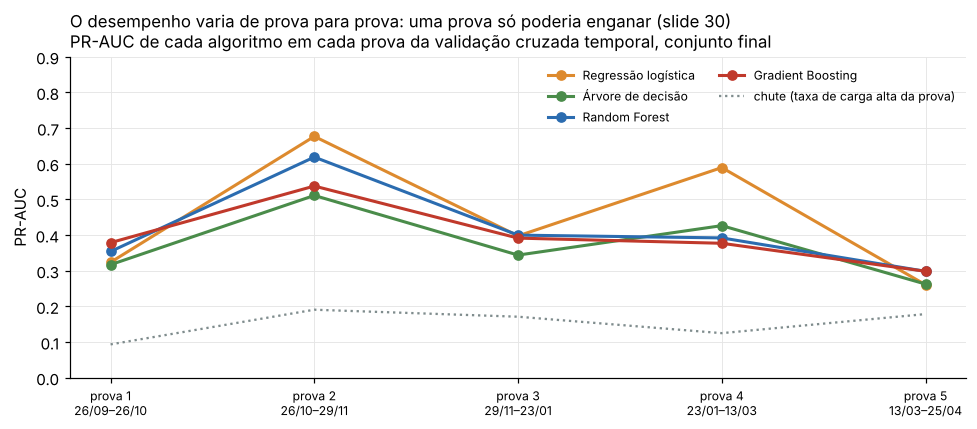

In [8]:
# Gráfico 02: PR-AUC prova a prova (a CV temporal anda no tempo)
fig, ax = plt.subplots(figsize=(9, 4))
for alg in ALGOS_REAIS:
    v = d.loc[alg, "PR-AUC_por_prova"]
    ax.plot(range(1, 6), v, marker="o", ms=6, lw=2, color=COR_ALGO[alg], label=alg)
taxa_prova = [treino.loc[b, "carga_alta"].mean() for _, b in CV]
ax.plot(range(1, 6), taxa_prova, ls=":", color=CINZA, lw=1.5, label="chute (taxa de carga alta da prova)")
ax.set_xticks(range(1, 6), [f"prova {i}\n{p}" for i, p in enumerate(periodo_dobra, 1)], fontsize=8)
ax.set_ylabel("PR-AUC")
ax.set_ylim(0, 0.9)
ax.set_title("O desempenho varia de prova para prova: uma prova só poderia enganar (slide 30)\n"
             "PR-AUC de cada algoritmo em cada prova da validação cruzada temporal, conjunto final",
             loc="left", fontsize=11)
ax.legend(fontsize=8, frameon=False, ncol=2)
salvar("02_pr_auc_por_prova")

## 7. Ajuste de hiperparâmetros (slide 24)

Os "botões do forno" de cada algoritmo, escolhidos com `GridSearchCV` **usando as mesmas 5
provas temporais** e PR-AUC como nota. O teste não participa (slide 35). Grades pequenas: com
~2.500 cestões no treino, grade grande é convite a decorar a validação cruzada.

| Algoritmo | Botões testados |
|---|---|
| Logística | `C` (força da regularização: menor = coeficientes mais contidos) |
| Árvore | `max_depth` (nº de perguntas), `min_samples_leaf` |
| Random Forest | `max_depth`, `min_samples_leaf`, `max_features` |
| Gradient Boosting | `learning_rate`, `n_estimators`, `max_depth` |

In [9]:
GRADES = {
    "Regressão logística": {"modelo__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    "Árvore de decisão": {"modelo__max_depth": [2, 3, 4, 5, 6, 8], "modelo__min_samples_leaf": [10, 30, 60]},
    "Random Forest": {"modelo__max_depth": [4, 8, None], "modelo__min_samples_leaf": [5, 20, 50],
                      "modelo__max_features": ["sqrt", 0.5]},
    "Gradient Boosting": {"modelo__learning_rate": [0.03, 0.1], "modelo__n_estimators": [100, 300],
                          "modelo__max_depth": [2, 3]},
}
ajustados, linhas = {}, []
for nome_conj, cols in CONJUNTOS.items():
    for alg in ALGOS_REAIS:
        busca = GridSearchCV(algoritmos(n_jobs_rf=1)[alg], GRADES[alg], cv=CV, scoring="average_precision",
                             n_jobs=-1).fit(treino[cols], y_tr)
        melhor = busca.best_estimator_      # já re-treinado no treino inteiro
        ajustados[(nome_conj, alg)] = melhor
        p = melhor.predict_proba(valid[cols])[:, 1]
        i = busca.best_index_
        linhas.append({"conjunto": nome_conj, "algoritmo": alg, "n_features": len(cols),
                       "complexidade": COMPLEXIDADE[alg],
                       "hiperparametros": {k.replace("modelo__", ""): v for k, v in busca.best_params_.items()},
                       "CV_PR-AUC": busca.best_score_,
                       "CV_PR-AUC_dp": busca.cv_results_["std_test_score"][i],
                       "val_PR-AUC": average_precision_score(y_va, p), "val_ROC-AUC": roc_auc_score(y_va, p)})
tab_ajuste = pd.DataFrame(linhas)
fab = tab_fabrica.set_index(["conjunto", "algoritmo"])["val_PR-AUC"]
tab_ajuste["ganho_val_vs_fabrica"] = [r["val_PR-AUC"] - fab[(r["conjunto"], r["algoritmo"])]
                                      for _, r in tab_ajuste.iterrows()]
tab_ajuste.round(3)

,conjunto,algoritmo,n_features,complexidade,hiperparametros,CV_PR-AUC,CV_PR-AUC_dp,val_PR-AUC,val_ROC-AUC,ganho_val_vs_fabrica
0,final (6),Regressão logística,6,1,{'C': 0.01},0.461,0.159,0.291,0.671,0.005
1,final (6),Árvore de decisão,6,2,"{'max_depth': 4, 'min_samples_leaf': 30}",0.376,0.097,0.296,0.672,0.000
2,final (6),Random Forest,6,3,"{'max_depth': 8, 'max_features': 'sqrt', 'min_...",0.437,0.142,0.377,0.719,-0.050
3,final (6),Gradient Boosting,6,4,"{'learning_rate': 0.03, 'max_depth': 2, 'n_est...",0.442,0.119,0.402,0.713,0.007
4,consenso (18),Regressão logística,18,1,{'C': 1},0.448,0.136,0.302,0.695,0.000
5,consenso (18),Árvore de decisão,18,2,"{'max_depth': 5, 'min_samples_leaf': 30}",0.378,0.088,0.334,0.705,0.032
6,consenso (18),Random Forest,18,3,"{'max_depth': None, 'max_features': 0.5, 'min_...",0.434,0.124,0.394,0.746,-0.035
7,consenso (18),Gradient Boosting,18,4,"{'learning_rate': 0.03, 'max_depth': 2, 'n_est...",0.430,0.133,0.411,0.718,0.017
8,final sem histórico (4),Regressão logística,4,1,{'C': 0.01},0.384,0.162,0.198,0.555,0.003
9,final sem histórico (4),Árvore de decisão,4,2,"{'max_depth': 5, 'min_samples_leaf': 10}",0.334,0.105,0.242,0.574,0.015


### O que funcionava antes de maio não é o que funciona depois

Comparando a nota na CV temporal (treino, ago/2025–abr/2026) com a nota na validação
(abr–jun/2026):
- a **regressão logística** é a melhor na CV e a pior na validação;
- o **ajuste de hiperparâmetros**, feito na CV, quase nunca melhora a validação, e na Random
  Forest com as features finais piora bastante.

As duas coisas têm a mesma causa: o treino é todo do regime antigo (antes de maio/2026, com
mais material pesado e mais ciclos), e a CV dentro dele só sabe premiar o que funciona nesse
regime. Por isso:
- a versão **de fábrica** de cada algoritmo continua candidata na seção 8 (ela também é uma
  escolha de hiperparâmetros feita antes de ver os dados, e no slide 22 a Random Forest
  "funciona bem de fábrica");
- a **validação** decide entre os candidatos, porque é o período mais parecido com o uso real.

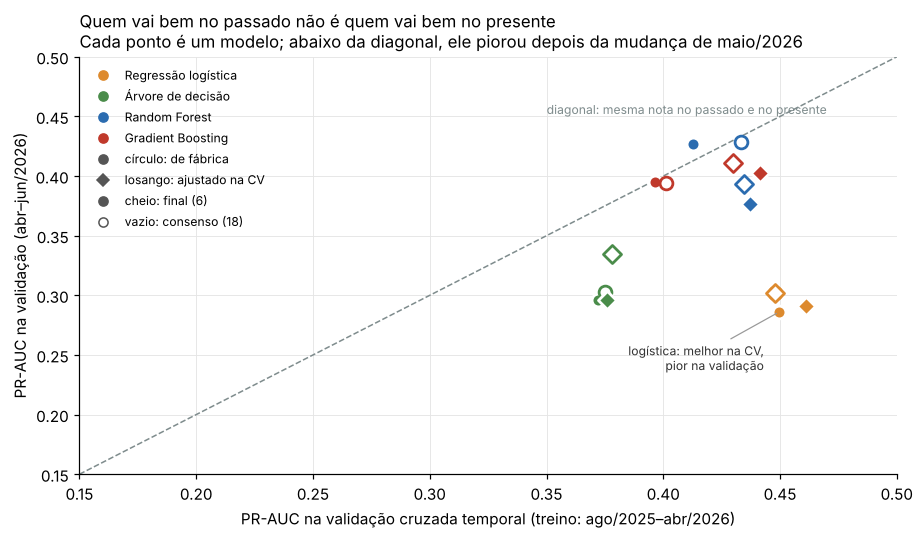

In [10]:
# Gráfico 03: CV x validação (plano A, fábrica e ajustados)
fig, ax = plt.subplots(figsize=(8.5, 5))
for etapa, tab, marcador in [("de fábrica", tab_fabrica, "o"), ("ajustado na CV", tab_ajuste, "D")]:
    t = tab[tab.conjunto.isin([NOME_FINAL, NOME_CONS]) & tab.algoritmo.isin(ALGOS_REAIS)]
    for _, r in t.iterrows():
        cheio = r["conjunto"] == NOME_FINAL
        ax.scatter(r["CV_PR-AUC"], r["val_PR-AUC"], s=70, marker=marcador, zorder=3, linewidth=1.8,
                   facecolor=COR_ALGO[r["algoritmo"]] if cheio else "white",
                   edgecolor="white" if cheio else COR_ALGO[r["algoritmo"]])
lim_ax = [0.15, 0.5]
ax.plot(lim_ax, lim_ax, color=CINZA, lw=1, ls="--")
ax.annotate("diagonal: mesma nota no passado e no presente", (0.47, 0.47), xytext=(0, -14), textcoords="offset points",
            fontsize=8, color=CINZA, ha="right")
lr = tab_fabrica[(tab_fabrica.conjunto == NOME_FINAL) & (tab_fabrica.algoritmo == "Regressão logística")].iloc[0]
ax.annotate("logística: melhor na CV,\npior na validação", (lr["CV_PR-AUC"], lr["val_PR-AUC"]),
            xytext=(-10, -38), textcoords="offset points", fontsize=8, ha="right", color="#333",
            arrowprops=dict(arrowstyle="-", color="#999", lw=0.8))
from matplotlib.lines import Line2D
leg = [Line2D([], [], marker="o", ls="", color=COR_ALGO[a], label=a) for a in ALGOS_REAIS]
leg += [Line2D([], [], marker="o", ls="", color="#555", label="círculo: de fábrica"),
        Line2D([], [], marker="D", ls="", color="#555", label="losango: ajustado na CV"),
        Line2D([], [], marker="o", ls="", markerfacecolor="#555", markeredgecolor="#555", label=f"cheio: {NOME_FINAL}"),
        Line2D([], [], marker="o", ls="", markerfacecolor="white", markeredgecolor="#555", label=f"vazio: {NOME_CONS}")]
ax.legend(handles=leg, fontsize=8, frameon=False, loc="upper left")
ax.set_xlim(*lim_ax); ax.set_ylim(*lim_ax)
ax.set_xlabel("PR-AUC na validação cruzada temporal (treino: ago/2025–abr/2026)")
ax.set_ylabel("PR-AUC na validação (abr–jun/2026)")
ax.set_title("Quem vai bem no passado não é quem vai bem no presente\n"
             "Cada ponto é um modelo; abaixo da diagonal, ele piorou depois da mudança de maio/2026",
             loc="left", fontsize=11)
salvar("03_cv_vs_validacao")

## 7b. Desbalanceamento: pesos × sem peso × subamostragem (Guia de Modelagem §4.4)

Só ~16% dos cestões têm carga alta. O Guia lista as opções; aqui elas são comparadas na Random
Forest de fábrica com as features finais, nas mesmas provas temporais e na validação:
- **sem peso**: o algoritmo puro;
- **pesos de classe** (`balanced_subsample`), a opção usada no projeto;
- **subamostragem** da classe "normal" até 1:1, feita **só dentro do treino de cada prova**
  (nunca na validação, que tem de manter a proporção real de eventos).

Não usamos SMOTE: ele cria cestões sintéticos interpolando outros, o que pode gerar receitas
fisicamente impossíveis (Guia §4.4), e a PR-AUC não depende do limiar, que é ajustado à parte na
seção 9. Esta comparação **não muda a escolha** da seção 8; ela documenta a estratégia.

In [11]:
def rf_desbal(peso):
    return montar(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight=peso,
                                         n_jobs=-1, random_state=SEED))

def subamostrar(X, y, seed=SEED):
    rng_s = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    keep = np.concatenate([pos, rng_s.choice(neg, size=len(pos), replace=False)])
    return X.iloc[keep], y.iloc[keep]

def nota_desbal(estrategia):
    notas = []
    for a, b in CV + [(np.arange(len(treino)), None)]:
        Xa, ya = treino.iloc[a][FEAT_FINAL], y_tr.iloc[a]
        if estrategia == "subamostragem 1:1 (no treino)":
            Xa, ya = subamostrar(Xa, ya)
        m = rf_desbal("balanced_subsample" if estrategia.startswith("pesos") else None).fit(Xa, ya)
        if b is None:
            p = m.predict_proba(valid[FEAT_FINAL])[:, 1]
            return {"estrategia": estrategia, "CV_PR-AUC": np.mean(notas), "CV_PR-AUC_dp": np.std(notas),
                    "val_PR-AUC": average_precision_score(y_va, p), "val_ROC-AUC": roc_auc_score(y_va, p),
                    "chance_media_val": p.mean(), "taxa_real_val": y_va.mean()}
        notas.append(average_precision_score(treino.iloc[b]["carga_alta"], m.predict_proba(treino.iloc[b][FEAT_FINAL])[:, 1]))

tab_desbal = pd.DataFrame([nota_desbal(e) for e in ["sem peso", "pesos de classe (balanced_subsample)",
                                                     "subamostragem 1:1 (no treino)"]]).set_index("estrategia")
tab_desbal.round(3)

,CV_PR-AUC,CV_PR-AUC_dp,val_PR-AUC,val_ROC-AUC,chance_media_val,taxa_real_val
estrategia,,,,,,
sem peso,0.414,0.112,0.410,0.728,0.250,0.179
pesos de classe (balanced_subsample),0.413,0.109,0.427,0.731,0.413,0.179
subamostragem 1:1 (no treino),0.419,0.107,0.411,0.729,0.584,0.179


## 8. A escada: subir de complexidade só se valer a pena (slide 33)

**Regra:**
1. Candidatos: cada algoritmo **de fábrica e ajustado**, nos conjuntos **final (6)** e
   **consenso (18)**. O conjunto sem histórico é o plano B (ver abaixo).
2. Nota: PR-AUC na **validação**.
3. Fica o **mais simples** (degrau mais baixo da escada; depois, menos features) cuja nota está
   a **no máximo 0,02** da melhor. "Se a logística quase empata com o boosting, a logística pode
   ser a melhor escolha" (slide 33).

**Quão grande é uma diferença de 0,02?** A validação tem só ~90 cestões com carga alta. O
intervalo de 90% da PR-AUC (bootstrap por corrida) mostra quanto ela oscilaria com outra amostra
do mesmo período: diferenças menores que essa oscilação são empate.

**Plano B (sem histórico):** as features `taxa_ca_ult5/10` usam o resultado das corridas
anteriores. Se a EVCOMX disser que esse resultado não está disponível na hora de prever, o
modelo não pode usá-las. Aplicamos a mesma regra ao conjunto sem histórico, para já termos o
substituto pronto.

In [12]:
TOL = 0.02
modelos = {**{(c, a, "fábrica"): m for (c, a), m in de_fabrica.items() if a in ALGOS_REAIS},
           **{(c, a, "ajustado"): m for (c, a), m in ajustados.items()}}
cand = pd.concat([
    tab_fabrica[tab_fabrica.algoritmo.isin(ALGOS_REAIS)].drop(columns="PR-AUC_por_prova")
        .assign(versao="fábrica", hiperparametros="fábrica"),
    tab_ajuste.drop(columns="ganho_val_vs_fabrica").assign(versao="ajustado")], ignore_index=True)
cand["complexidade"] = cand["algoritmo"].map(COMPLEXIDADE)

# bootstrap por corrida na validação
rng = np.random.default_rng(SEED)
corridas_va = valid["cd_corrida"].unique()
idx_corrida = valid.groupby("cd_corrida").indices
amostras = [np.concatenate([idx_corrida[c] for c in rng.choice(corridas_va, len(corridas_va))]) for _ in range(500)]
def ic90(p):
    v = [average_precision_score(y_va.values[a], p[a]) for a in amostras]
    return round(float(np.percentile(v, 5)), 3), round(float(np.percentile(v, 95)), 3)
p_val = {k: m.predict_proba(valid[CONJUNTOS[k[0]]])[:, 1] for k, m in modelos.items()}
ics = {k: ic90(p) for k, p in p_val.items()}
cand["val_IC90"] = [ics[(r.conjunto, r.algoritmo, r.versao)] for r in cand.itertuples()]

def subir_escada(tab):
    teto = tab["val_PR-AUC"].max()
    ok = tab[tab["val_PR-AUC"] >= teto - TOL]
    return ok.sort_values(["complexidade", "n_features", "val_PR-AUC"], ascending=[True, True, False]).iloc[0], teto

esc_A, teto_A = subir_escada(cand[cand.conjunto.isin([NOME_FINAL, NOME_CONS])])
esc_B, teto_B = subir_escada(cand[cand.conjunto == NOME_SEMH])
for rot, esc, teto in [("PLANO A (com histórico)", esc_A, teto_A), ("PLANO B (sem histórico)", esc_B, teto_B)]:
    print(f"{rot}: {esc['algoritmo']} {esc['versao']} | {esc['conjunto']} | {esc['hiperparametros']}")
    print(f"   PR-AUC validação {esc['val_PR-AUC']:.3f}, IC90 {esc['val_IC90']} (melhor do grupo: {teto:.3f}) | "
          f"CV {esc['CV_PR-AUC']:.3f} ± {esc['CV_PR-AUC_dp']:.3f}")
cand.sort_values("val_PR-AUC", ascending=False)[
    ["conjunto", "algoritmo", "versao", "hiperparametros", "CV_PR-AUC", "val_PR-AUC", "val_IC90"]].round(3)

PLANO A (com histórico): Random Forest fábrica | final (6) | fábrica
   PR-AUC validação 0.427, IC90 (0.346, 0.516) (melhor do grupo: 0.428) | CV 0.413 ± 0.109
PLANO B (sem histórico): Random Forest ajustado | final sem histórico (4) | {'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 5}
   PR-AUC validação 0.316, IC90 (0.248, 0.403) (melhor do grupo: 0.316) | CV 0.368 ± 0.096


,conjunto,algoritmo,versao,hiperparametros,CV_PR-AUC,val_PR-AUC,val_IC90
6,consenso (18),Random Forest,fábrica,fábrica,0.433,0.428,"(0.351, 0.518)"
2,final (6),Random Forest,fábrica,fábrica,0.413,0.427,"(0.346, 0.516)"
19,consenso (18),Gradient Boosting,ajustado,"{'learning_rate': 0.03, 'max_depth': 2, 'n_est...",0.430,0.411,"(0.332, 0.503)"
15,final (6),Gradient Boosting,ajustado,"{'learning_rate': 0.03, 'max_depth': 2, 'n_est...",0.442,0.402,"(0.319, 0.49)"
3,final (6),Gradient Boosting,fábrica,fábrica,0.397,0.395,"(0.318, 0.486)"
7,consenso (18),Gradient Boosting,fábrica,fábrica,0.401,0.394,"(0.321, 0.489)"
18,consenso (18),Random Forest,ajustado,"{'max_depth': None, 'max_features': 0.5, 'min_...",0.434,0.394,"(0.317, 0.488)"
14,final (6),Random Forest,ajustado,"{'max_depth': 8, 'max_features': 'sqrt', 'min_...",0.437,0.377,"(0.296, 0.466)"
17,consenso (18),Árvore de decisão,ajustado,"{'max_depth': 5, 'min_samples_leaf': 30}",0.378,0.334,"(0.265, 0.407)"
22,final sem histórico (4),Random Forest,ajustado,"{'max_depth': 4, 'max_features': 'sqrt', 'min_...",0.368,0.316,"(0.248, 0.403)"


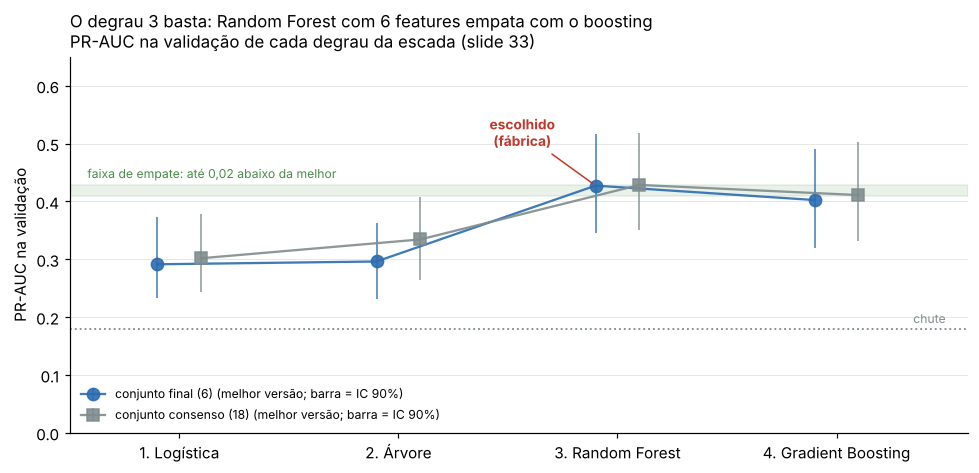

In [13]:
# Gráfico 04: a escada, no plano A (melhor versão de cada degrau, com IC90)
fig, ax = plt.subplots(figsize=(9, 4.4))
for nome_conj, marcador, desl, cor in [(NOME_FINAL, "o", -0.1, AZUL), (NOME_CONS, "s", 0.1, CINZA)]:
    t = cand[cand.conjunto == nome_conj].sort_values("val_PR-AUC").groupby("algoritmo").tail(1).sort_values("complexidade")
    x = t["complexidade"] + desl
    lo = t["val_PR-AUC"] - t["val_IC90"].str[0]
    hi = t["val_IC90"].str[1] - t["val_PR-AUC"]
    ax.errorbar(x, t["val_PR-AUC"], yerr=[lo, hi], fmt=marcador + "-", ms=8, lw=1.5, color=cor,
                elinewidth=1, alpha=0.9, label=f"conjunto {nome_conj} (melhor versão; barra = IC 90%)")
ax.axhspan(teto_A - TOL, teto_A, color=VERDE, alpha=0.12)
ax.annotate(f"faixa de empate: até {TOL:.2f} abaixo da melhor".replace(".", ","), (0.58, teto_A + 0.012), fontsize=8, color=VERDE)
x_esc = esc_A["complexidade"] + (-0.1 if esc_A["conjunto"] == NOME_FINAL else 0.1)
ax.annotate(f"escolhido\n({esc_A['versao']})", (x_esc, esc_A["val_PR-AUC"]), xytext=(-48, 26),
            textcoords="offset points", ha="center", fontsize=9, fontweight="bold", color=VERMELHO,
            arrowprops=dict(arrowstyle="-", color=VERMELHO, lw=1))
ax.axhline(y_va.mean(), color=CINZA, ls=":", lw=1.2)
ax.annotate("chute", (4.35, y_va.mean()), xytext=(0, 4), textcoords="offset points", fontsize=8, color=CINZA)
ax.set_xticks([1, 2, 3, 4], ["1. Logística", "2. Árvore", "3. Random Forest", "4. Gradient Boosting"])
ax.set_xlim(0.5, 4.6)
ax.set_ylim(0, 0.65)
ax.set_ylabel("PR-AUC na validação")
ax.set_title(f"O degrau 3 basta: {esc_A['algoritmo']} com {esc_A['n_features']} features empata com o boosting\n"
             "PR-AUC na validação de cada degrau da escada (slide 33)", loc="left", fontsize=11)
ax.legend(fontsize=8, frameon=False, loc="lower left")
ax.grid(axis="x", visible=False)
salvar("04_escada_de_complexidade")

## 9. O limiar de decisão (slide 16)

O modelo devolve uma **chance** de carga alta; o limiar transforma a chance em alarme. O padrão
de 50% não serve com classe rara. O limiar é escolhido **na validação**, com o modelo treinado
só no treino, e depende da resposta da EVCOMX à pergunta 3 do e-mail:

| Se a EVCOMX disser que… | Critério | Limiar |
|---|---|---|
| carga alta não detectada é pior | F2 (recall pesa 2× a precisão) | **"não deixar passar"** |
| os dois erros pesam igual | F1 | **"equilíbrio"** |
| alarme falso é pior | F0,5 (precisão pesa 2×) | **"evitar alarme falso"** |

Restrição: o limiar não pode disparar alarme em **mais da metade dos cestões** da validação.
Sem ela, com um modelo fraco o F2 escolhe "alarme em tudo" (recall 100%, nenhuma utilidade).
O valor de 50% é uma suposição nossa, para confirmar com a EVCOMX junto com a pergunta 3.

Para a operação, traduzimos cada limiar em **alarmes a cada 100 cestões**.

In [14]:
CENARIOS = {"não deixar passar (F2)": 2.0, "equilíbrio (F1)": 1.0, "evitar alarme falso (F0,5)": 0.5}

ALARMES_MAX = 0.5   # um "modelo" que dispara em mais da metade dos cestões não ajuda a operação

def escolher_limiares(y, p):
    prec, rec, lims = precision_recall_curve(y, p)
    prec, rec = prec[:-1], rec[:-1]
    taxa_alarme = np.array([(p >= l).mean() for l in lims])
    out = {}
    for nome, beta in CENARIOS.items():
        f = (1 + beta**2) * prec * rec / np.clip(beta**2 * prec + rec, 1e-12, None)
        f[taxa_alarme > ALARMES_MAX] = -1
        out[nome] = float(lims[np.argmax(f)])
    return out

def medir(y, p, lim):
    prev = p >= lim
    vp = int((prev & (y == 1)).sum())
    return {"limiar": lim, "acuracia": accuracy_score(y, prev), "recall": recall_score(y, prev),
            "precisao": precision_score(y, prev, zero_division=0), "F1": f1_score(y, prev),
            "alarmes_por_100": 100 * prev.mean(), "acertos_por_100": 100 * vp / len(y),
            "cargas_altas_por_100": 100 * y.mean()}

def preparar(esc):
    cols = CONJUNTOS[esc["conjunto"]]
    modelo = modelos[(esc["conjunto"], esc["algoritmo"], esc["versao"])]
    return modelo, cols, modelo.predict_proba(valid[cols])[:, 1]

modelo_A, cols_A, p_va_A = preparar(esc_A)
modelo_B, cols_B, p_va_B = preparar(esc_B)
lim_A, lim_B = escolher_limiares(y_va, p_va_A), escolher_limiares(y_va, p_va_B)
tab_limiar = pd.DataFrame([{"plano": plano, "cenario": c, **medir(y_va, p, lims[c])}
                           for plano, p, lims in [("A", p_va_A, lim_A), ("B", p_va_B, lim_B)]
                           for c in CENARIOS])
tab_limiar.round(3)

,plano,cenario,limiar,acuracia,recall,precisao,F1,alarmes_por_100,acertos_por_100,cargas_altas_por_100
0,A,não deixar passar (F2),0.407,0.624,0.761,0.290,0.420,46.979,13.645,17.934
1,A,equilíbrio (F1),0.542,0.733,0.609,0.357,0.450,30.604,10.916,17.934
2,A,"evitar alarme falso (F0,5)",0.768,0.838,0.261,0.615,0.366,7.602,4.678,17.934
3,B,não deixar passar (F2),0.511,0.567,0.641,0.238,0.347,48.343,11.501,17.934
4,B,equilíbrio (F1),0.806,0.784,0.348,0.386,0.366,16.179,6.238,17.934
5,B,"evitar alarme falso (F0,5)",0.827,0.807,0.283,0.441,0.344,11.501,5.068,17.934


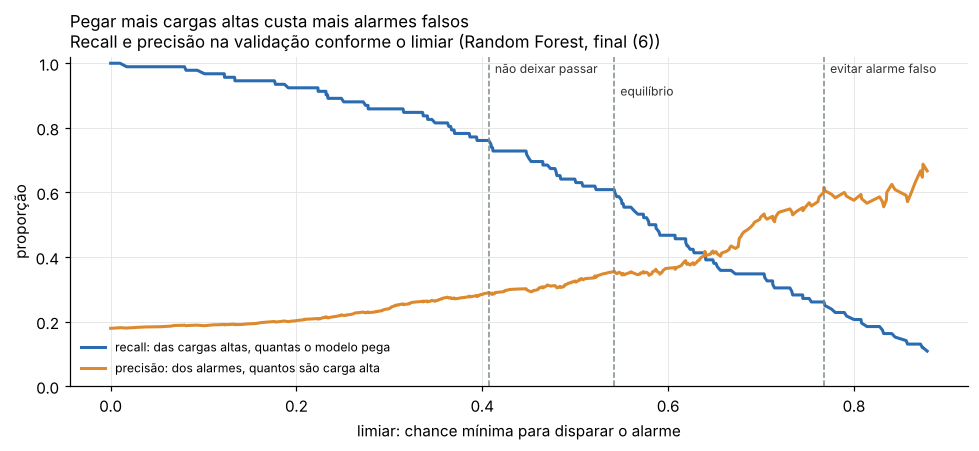

In [15]:
# Gráfico 05: recall e precisão conforme o limiar (plano A, validação)
prec, rec, lims = precision_recall_curve(y_va, p_va_A)
n_alarmes = np.array([(p_va_A >= l).sum() for l in lims])
manter = n_alarmes >= 15                      # com menos de 15 alarmes a precisão vira ruído
prec, rec, lims = prec[:-1][manter], rec[:-1][manter], lims[manter]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(lims, rec, color=AZUL, lw=2, label="recall: das cargas altas, quantas o modelo pega")
ax.plot(lims, prec, color=LARANJA, lw=2, label="precisão: dos alarmes, quantos são carga alta")
for (nome, lim), dy in zip(lim_A.items(), [0.97, 0.90, 0.97]):
    ax.axvline(lim, color=CINZA, ls="--", lw=1)
    ax.annotate(nome.split(" (")[0], (lim, dy), xytext=(4, 0), textcoords="offset points", fontsize=8, color="#333")
ax.set_xlabel("limiar: chance mínima para disparar o alarme")
ax.set_ylabel("proporção")
ax.set_ylim(0, 1.02)
ax.set_title("Pegar mais cargas altas custa mais alarmes falsos\n"
             f"Recall e precisão na validação conforme o limiar ({esc_A['algoritmo']}, {esc_A['conjunto']})",
             loc="left", fontsize=11)
ax.legend(fontsize=8, frameon=False, loc="lower left")
salvar("05_limiar_recall_precisao")

## 10. Conferência no TESTE — uma única vez (slides 35 e 36)

Tudo já está decidido antes desta célula: algoritmo, hiperparâmetros, conjunto de features e os
três limiares (vindos da validação). O teste (jun–ago/2026) só mede.

Reportamos os planos A e B e os três cenários de limiar porque a escolha entre eles depende das
respostas da EVCOMX, **não** do teste. O baseline entra na mesma tabela, na mesma métrica.

In [16]:
p_te_A = modelo_A.predict_proba(teste[cols_A])[:, 1]
p_te_B = modelo_B.predict_proba(teste[cols_B])[:, 1]
res = []
for plano, esc, p, lims in [("A (com histórico)", esc_A, p_te_A, lim_A), ("B (sem histórico)", esc_B, p_te_B, lim_B)]:
    for c in CENARIOS:
        res.append({"plano": plano, "modelo": f"{esc['algoritmo']} {esc['versao']} | {esc['conjunto']}", "cenario": c,
                    "PR-AUC": average_precision_score(y_te, p), "ROC-AUC": roc_auc_score(y_te, p),
                    **medir(y_te, p, lims[c])})
dummy = algoritmos()["Baseline: maioria"].fit(treino[cols_A], y_tr)
p_dummy = dummy.predict_proba(teste[cols_A])[:, 1]
res.append({"plano": "baseline", "modelo": "Baseline: maioria", "cenario": "sempre 'normal'",
            "PR-AUC": average_precision_score(y_te, p_dummy), "ROC-AUC": 0.5, **medir(y_te, p_dummy, 0.5)})
alarme_vol_te = teste[COL_VOL] > LIM_VOL
res.append({"plano": "baseline", "modelo": "Baseline: regra de volume", "cenario": f"volume > {LIM_VOL:.1f} m³ (limiar do treino)",
            "PR-AUC": average_precision_score(y_te, teste[COL_VOL]), "ROC-AUC": roc_auc_score(y_te, teste[COL_VOL]),
            **medir(y_te, teste[COL_VOL].to_numpy(), np.nextafter(LIM_VOL, np.inf))})
tab_teste = pd.DataFrame(res)
tab_teste.round(3)

,plano,modelo,cenario,PR-AUC,ROC-AUC,limiar,acuracia,recall,precisao,F1,alarmes_por_100,acertos_por_100,cargas_altas_por_100
0,A (com histórico),Random Forest fábrica | final (6),não deixar passar (F2),0.391,0.769,0.407,0.691,0.760,0.288,0.418,38.447,11.068,14.563
1,A (com histórico),Random Forest fábrica | final (6),equilíbrio (F1),0.391,0.769,0.542,0.765,0.627,0.336,0.437,27.184,9.126,14.563
2,A (com histórico),Random Forest fábrica | final (6),"evitar alarme falso (F0,5)",0.391,0.769,0.768,0.845,0.333,0.455,0.385,10.680,4.854,14.563
3,B (sem histórico),Random Forest ajustado | final sem histórico (4),não deixar passar (F2),0.228,0.611,0.511,0.528,0.640,0.182,0.283,51.262,9.320,14.563
4,B (sem histórico),Random Forest ajustado | final sem histórico (4),equilíbrio (F1),0.228,0.611,0.806,0.792,0.293,0.289,0.291,14.757,4.272,14.563
5,B (sem histórico),Random Forest ajustado | final sem histórico (4),"evitar alarme falso (F0,5)",0.228,0.611,0.827,0.810,0.227,0.298,0.258,11.068,3.301,14.563
6,baseline,Baseline: maioria,sempre 'normal',0.146,0.500,0.500,0.854,0.000,0.000,0.000,0.000,0.000,14.563
7,baseline,Baseline: regra de volume,volume > 56.4 m³ (limiar do treino),0.149,0.521,56.364,0.476,0.533,0.145,0.229,53.398,7.767,14.563


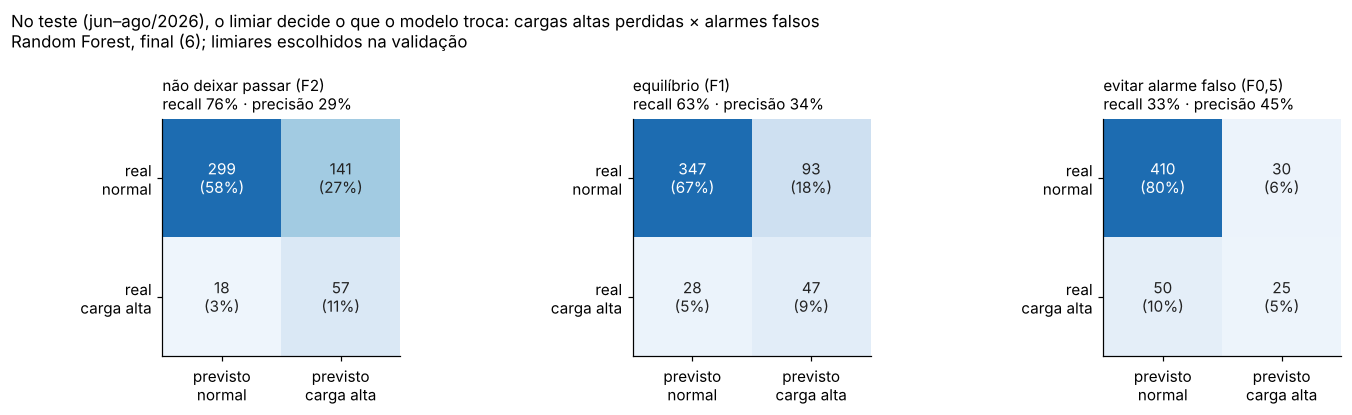

In [17]:
# Gráfico 06: matrizes de confusão no teste (plano A), nos três cenários
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, c in zip(axes, CENARIOS):
    m = confusion_matrix(y_te, p_te_A >= lim_A[c])
    ax.imshow(m, cmap="Blues", vmin=0, vmax=m.max() * 1.3)
    for (i, j), v in np.ndenumerate(m):
        ax.text(j, i, f"{v}\n({100 * v / m.sum():.0f}%)", ha="center", va="center", fontsize=10,
                color="white" if v > m.max() * 0.7 else "#222")
    ax.set_xticks([0, 1], ["previsto\nnormal", "previsto\ncarga alta"])
    ax.set_yticks([0, 1], ["real\nnormal", "real\ncarga alta"])
    r = tab_teste[(tab_teste.plano.str.startswith("A")) & (tab_teste.cenario == c)].iloc[0]
    ax.set_title(f"{c}\nrecall {r['recall']:.0%} · precisão {r['precisao']:.0%}", loc="left", fontsize=10)
    ax.grid(False)
fig.suptitle(f"No teste (jun–ago/2026), o limiar decide o que o modelo troca: cargas altas perdidas × alarmes falsos\n"
             f"{esc_A['algoritmo']}, {esc_A['conjunto']}; limiares escolhidos na validação",
             x=0.01, ha="left", fontsize=11)
salvar("06_matriz_confusao_teste")

## 11. Explicar o modelo escolhido (slide 32: "preciso explicar cada decisão?")

- **Permutação na validação:** quanto a PR-AUC cai quando embaralhamos cada feature. Vale para
  qualquer algoritmo.
- **Coeficientes**, se o escolhido for a regressão logística: efeito de +1 desvio-padrão em cada
  feature na chance de carga alta (razão de chances).
- **Árvore rasa (3 perguntas)**, só para a apresentação: vira um fluxograma que o pátio entende
  (slide 18). Não é o modelo escolhido; a PR-AUC dela é mostrada para comparação.

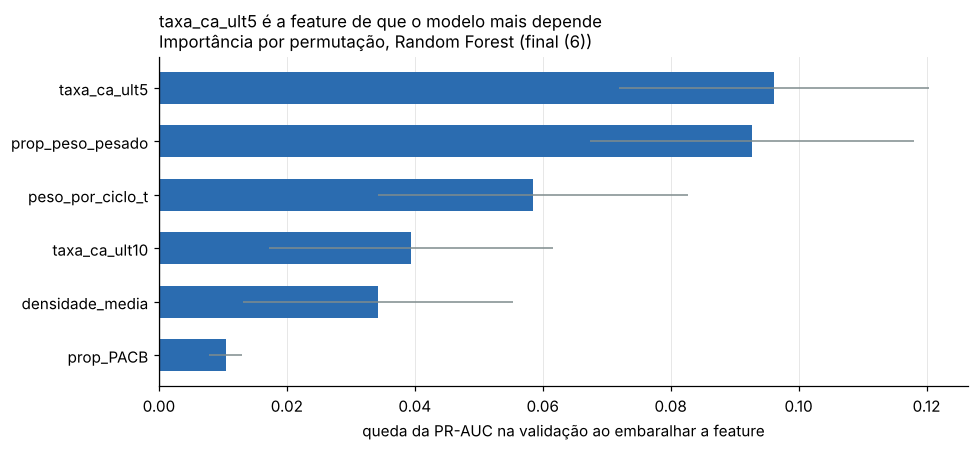

,queda_PR-AUC,dp
taxa_ca_ult5,0.096,0.024
prop_peso_pesado,0.093,0.025
peso_por_ciclo_t,0.058,0.024
taxa_ca_ult10,0.039,0.022
densidade_media,0.034,0.021
prop_PACB,0.010,0.003


In [18]:
perm = permutation_importance(modelo_A, valid[cols_A], y_va, scoring="average_precision",
                              n_repeats=30, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"queda_PR-AUC": perm.importances_mean, "dp": perm.importances_std},
                   index=cols_A).sort_values("queda_PR-AUC")
if esc_A["algoritmo"] == "Regressão logística":
    coef = pd.Series(modelo_A.named_steps["modelo"].coef_[0], index=cols_A)
    imp["razao_de_chances_1dp"] = np.exp(coef).reindex(imp.index)

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(imp.index, imp["queda_PR-AUC"], xerr=imp["dp"], color=AZUL, height=0.6,
        error_kw=dict(ecolor=CINZA, lw=1))
if "razao_de_chances_1dp" in imp:
    for y, (v, rc) in enumerate(zip(imp["queda_PR-AUC"], imp["razao_de_chances_1dp"])):
        ax.annotate(f"chance ×{rc:.2f} por +1 dp", (max(v, 0), y), xytext=(6, -3), textcoords="offset points",
                    fontsize=8, color="#333")
ax.axvline(0, color="#333", lw=0.8)
ax.set_xlabel("queda da PR-AUC na validação ao embaralhar a feature")
ax.set_title(f"{imp.index[-1]} é a feature de que o modelo mais depende\n"
             f"Importância por permutação, {esc_A['algoritmo']} ({esc_A['conjunto']})", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
salvar("07_importancia_modelo_escolhido")
imp.iloc[::-1].round(3)

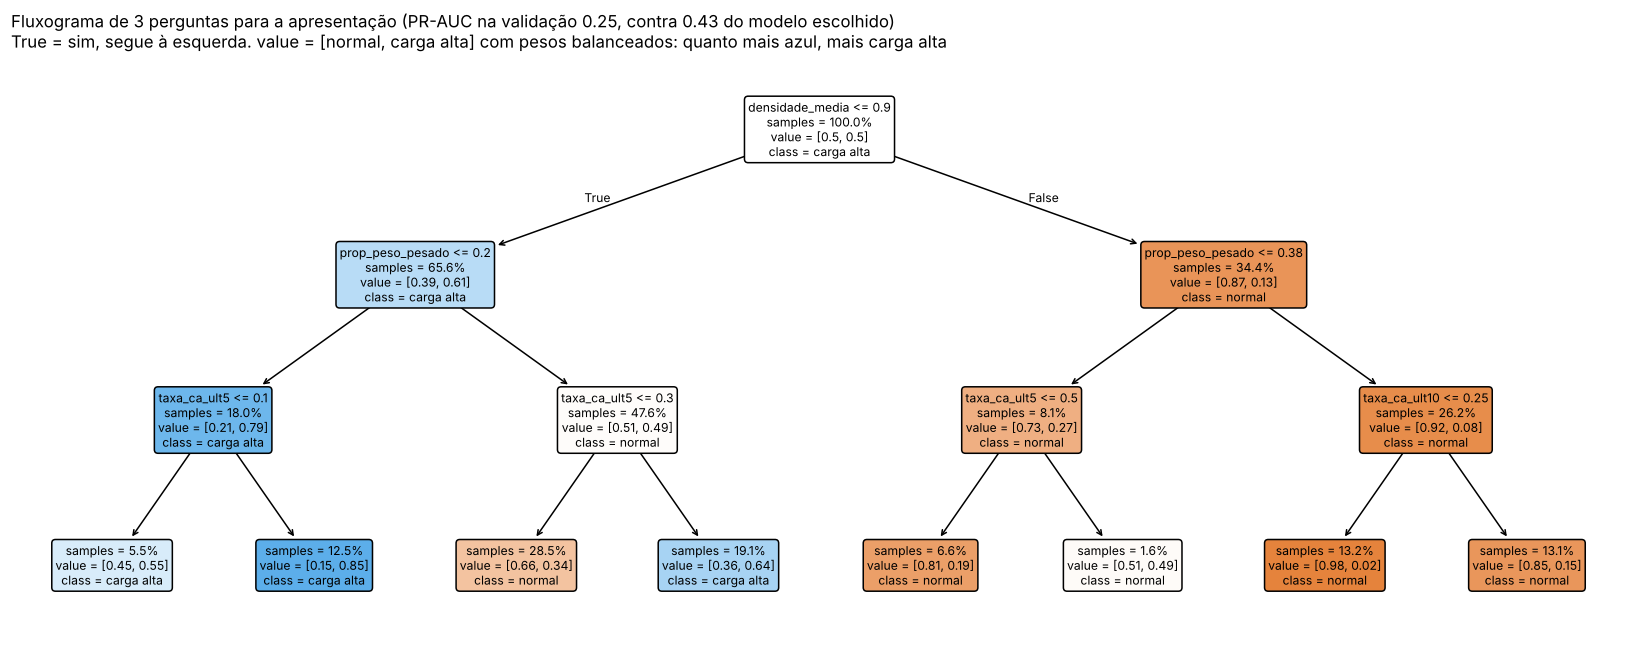

In [19]:
arvore = montar(DecisionTreeClassifier(max_depth=3, min_samples_leaf=30, class_weight="balanced",
                                       random_state=SEED)).fit(treino[FEAT_FINAL], y_tr)
pr_arvore = average_precision_score(y_va, arvore.predict_proba(valid[FEAT_FINAL])[:, 1])
fig, ax = plt.subplots(figsize=(15, 6))
plot_tree(arvore.named_steps["modelo"], feature_names=FEAT_FINAL, class_names=["normal", "carga alta"],
          filled=True, rounded=True, impurity=False, proportion=True, precision=2, fontsize=8, ax=ax)
ax.set_title(f"Fluxograma de 3 perguntas para a apresentação (PR-AUC na validação {pr_arvore:.2f}, "
             f"contra {esc_A['val_PR-AUC']:.2f} do modelo escolhido)\n"
             "True = sim, segue à esquerda. value = [normal, carga alta] com pesos balanceados: quanto mais azul, mais carga alta",
             loc="left", fontsize=11)
salvar("08_arvore_rasa_fluxograma")

## 12. Modelo para uso e arquivos gerados

O modelo avaliado no teste aprendeu só com o treino. Para **uso real**, re-treinamos o mesmo
algoritmo, com os mesmos hiperparâmetros, em **treino + validação**: assim ele conhece o regime
pós-maio/2026. A análise de modelos mede esse modelo no teste (o teste vem depois de treino e
validação, então é legítimo). Os limiares são os da validação e devem ser revistos quando houver
dados novos.

Guia de Modelagem §4.6: o `.joblib` guarda, **junto com o modelo**, a lista exata de features
(`features_`), os limiares (`limiares_`, sem arredondar) e a versão do scikit-learn
(`versao_sklearn_`). Continua sendo um `Pipeline`, então `predict_proba` funciona direto.

Arquivos:
- `comparacao_algoritmos.csv`: seção 6 (fábrica, com os três baselines) e seção 7 (ajustados), CV e validação;
- `desbalanceamento.csv`: seção 7b;
- `limiares_validacao.csv`: os três cenários de limiar, planos A e B;
- `resultado_teste.csv`: a conferência única no teste;
- `previsoes_validacao_teste.csv`: chance prevista por cestão (validação e teste), planos A e B;
- `modelo_final_planoA.joblib` / `modelo_final_planoB.joblib` + `modelo_final.json`
  (features, hiperparâmetros e limiares).

In [20]:
tv = pd.concat([treino, valid], ignore_index=True)
y_tv = tv["carga_alta"]
info = {}
for plano, esc, lims in [("A", esc_A, lim_A), ("B", esc_B, lim_B)]:
    cols = CONJUNTOS[esc["conjunto"]]
    final = modelos[(esc["conjunto"], esc["algoritmo"], esc["versao"])]

    producao = clone(final).fit(tv[cols], y_tv)
    import sklearn
    producao.features_ = list(cols)                       # Guia de Modelagem §4.6: modelo + features + limiar
    producao.limiares_ = {c: float(v) for c, v in lims.items()}
    producao.versao_sklearn_ = sklearn.__version__
    joblib.dump(producao, PASTA_SAIDA / f"modelo_final_plano{plano}.joblib")
    info[f"plano_{plano}"] = {"algoritmo": esc["algoritmo"], "versao": esc["versao"], "conjunto": esc["conjunto"],
                              "features": cols,
                              "hiperparametros": {k: v for k, v in final.named_steps["modelo"].get_params().items()
                                                  if k in GRADES[esc["algoritmo"]] or f"modelo__{k}" in GRADES[esc["algoritmo"]]
                                                  or k in ("n_estimators", "class_weight", "C")},
                              "treinado_com": "treino + validacao",
                              "limiares": {c: float(v) for c, v in lims.items()}}   # sem arredondar
(PASTA_SAIDA / "modelo_final.json").write_text(json.dumps(info, ensure_ascii=False, indent=2, default=str),
                                                encoding="utf-8")

comp = pd.concat([tab_fabrica[tab_fabrica.algoritmo.str.startswith("Baseline")]
                  .drop(columns="PR-AUC_por_prova").assign(versao="baseline"), cand], ignore_index=True)
comp.to_csv(PASTA_SAIDA / "comparacao_algoritmos.csv", index=False)
tab_limiar.to_csv(PASTA_SAIDA / "limiares_validacao.csv", index=False)
tab_teste.to_csv(PASTA_SAIDA / "resultado_teste.csv", index=False)
tab_desbal.to_csv(PASTA_SAIDA / "desbalanceamento.csv")
prev = pd.concat([valid[META[:3]].assign(prob_planoA=p_va_A, prob_planoB=p_va_B, carga_alta=y_va),
                  teste[META[:3]].assign(prob_planoA=p_te_A, prob_planoB=p_te_B, carga_alta=y_te)])
prev.to_csv(PASTA_SAIDA / "previsoes_validacao_teste.csv", index=False)
print(json.dumps(info, ensure_ascii=False, indent=2, default=str))
print("Salvos em", PASTA_SAIDA)

{
  "plano_A": {
    "algoritmo": "Random Forest",
    "versao": "fábrica",
    "conjunto": "final (6)",
    "features": [
      "densidade_media",
      "prop_peso_pesado",
      "peso_por_ciclo_t",
      "taxa_ca_ult5",
      "taxa_ca_ult10",
      "prop_PACB"
    ],
    "hiperparametros": {
      "class_weight": "balanced_subsample",
      "max_depth": null,
      "max_features": "sqrt",
      "min_samples_leaf": 5,
      "n_estimators": 300
    },
    "treinado_com": "treino + validacao",
    "limiares": {
      "não deixar passar (F2)": 0.4069341917806523,
      "equilíbrio (F1)": 0.5419377911335369,
      "evitar alarme falso (F0,5)": 0.7677382205391818
    }
  },
  "plano_B": {
    "algoritmo": "Random Forest",
    "versao": "ajustado",
    "conjunto": "final sem histórico (4)",
    "features": [
      "densidade_media",
      "prop_peso_pesado",
      "peso_por_ciclo_t",
      "prop_PACB"
    ],
    "hiperparametros": {
      "class_weight": "balanced_subsample",
      "max_dep